# What jump activity does to your hedge

**Jumps in financial time series, post 5 of 9**

> Pascal Lemieux is a quant with 15+ years across J.P. Morgan, RBC, Société Générale and First Abu Dhabi Bank, spanning structured products, derivatives pricing and volatility modelling. He now focuses on digital-asset derivatives: crypto options, volatility surfaces and hedging, including deep reinforcement learning for hedging and execution, work he began as co-founder of Affresco. M.Sc. Financial Mathematics, Bayes Business School.
>
> [LinkedIn](https://linkedin.com/in/pascal-lemieux) · [GitHub](https://github.com/PascalLemieux/jumps) · [The series](https://github.com/PascalLemieux/jumps#the-series)

This series tests what the jump literature claims against crypto market data, from 1-minute bars to tick trades. Every result is reproducible from the code in this repo. Every post asks the same question of a different effect: **is it real, or is it the measurement?**

| # | Post |
|:-:|------|
| 1 | [Most "jumps" are not jumps](01_jumps_vs_vol_bursts.ipynb) |
| 2 | [Intraday seasonality and false jumps](02_intraday_seasonality.ipynb) |
| 3 | [Bid-ask bounce and microstructure noise](03_microstructure_noise.ipynb) |
| 4 | [Finite or infinite activity](04_jump_activity.ipynb) |
| **5** | **What jump activity does to your hedge** |
| 6 | [Is volatility rough?](06_rough_volatility.ipynb) |
| 7 | Jumps or roughness in the smile? |
| 8 | The jump risk premium |
| 9 | Hedging with self-exciting jumps |

## The claim

Posts 1 to 4 argued about what large moves *are*. This one asks what they *cost*. Sell a short-dated Bitcoin option, delta-hedge it along the real price path, and vary how often you rebalance, from once a day to once a minute.

Textbook expectations: with a pure diffusion the hedging error shrinks like one over the square root of the number of rebalances, without limit. With jumps there is a floor, because no rebalancing schedule reacts to a discontinuity.

On 2,030 one-day at-the-money options, April 2021 to October 2026:

- **There is a floor, and it is high.** Hedged once a day the seller's error is 79% of the premium. Every hour: 41%. Every 15 minutes: 35%. Every minute: 32%. The last fifteen-fold increase in trading removes three points.
- **The floor is not jumps. It is volatility.** Give the hedger the day's realized volatility in advance and the error at one minute falls from 32% to 8%. Most of the floor is having sold at the wrong volatility level.
- **What remains is volatility again.** A diffusion with the same volatility would leave 2%, not 8%. The difference is *when* in the day the variance arrived: which hours were violent explains 95% of it. Whether a move inside the hour was a jump or a slide explains the rest.
- **Faster rebalancing buys less than in a diffusion.** The part of the error that rebalancing does remove shrinks more slowly than the square-root rule, and Bitcoin has to be rebalanced about twice as often as a diffusion for the same result.
- **And it is not free.** At one basis point per unit traded, going from 15 minutes to 1 minute costs ten points of premium to remove three points of risk.

**Data.** Binance spot 1-minute klines for BTCUSDT and Deribit's DVOL index, both public. Two small simulations serve as benchmarks.

**Status.** This is the first cut of a post that was pencilled, on the minimum data tier: the option is priced synthetically at DVOL, a 30-day index, not at the market's own one-day implied volatility. Section 8 says what that does and does not affect.

In [1]:
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore", category=RuntimeWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from jumps import hedging as hg
from jumps import plotting as jp
from jumps import seasonality as se
from jumps.data import load_dvol, load_klines

jp.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

close_all = load_klines("BTCUSDT", "2017-08", "2026-10")["close"]
close = close_all[close_all.index >= pd.Timestamp("2021-03-01", tz="UTC")]
dvol = load_dvol("BTC", "2021-04-01", "2026-11-01")["close"] / 100.0     # annualised, as a fraction

def build(days, weekday=None):
    """Non-overlapping windows starting at 08:00 UTC, with DVOL at the start and realized volatility."""
    starts, paths = hg.windows(close, days, start_hour=8, weekday=weekday, first="2021-04-02")
    implied = dvol.reindex(starts).to_numpy()
    ok = np.isfinite(implied)
    return starts[ok], paths[ok], implied[ok], hg.realised_volatility(paths[ok])

starts, paths, implied, realised = build(1)
print(f"{len(starts):,} one-day windows from {starts[0]:%Y-%m-%d} to {starts[-1]:%Y-%m-%d}, 08:00 to 08:00 UTC")
print(f"DVOL at the start: mean {100 * implied.mean():.0f}%.  Realized over the day: mean {100 * realised.mean():.0f}%.  "
      f"Correlation {np.corrcoef(implied, realised)[0, 1]:.2f}.")
print(f"Standard deviation of log(realized / DVOL): {np.std(np.log(realised / implied)):.2f}")

BTCUSDT 1m: 111 months loaded


2,030 one-day windows from 2021-04-02 to 2026-10-29, 08:00 to 08:00 UTC
DVOL at the start: mean 59%.  Realized over the day: mean 50%.  Correlation 0.62.
Standard deviation of log(realized / DVOL): 0.38


## 1. The experiment

At 08:00 UTC, Deribit's expiry time, sell a call struck at the current price, expiring 24 hours later. Hedge it with the underlying, rebalancing every $h$ minutes to the Black-Scholes delta. Rates and carry are zero. At expiry the seller's profit is

$$\text{P\&L} = C_0 - (S_T - K)^+ + \sum_j \delta_j\,(S_{t_{j+1}} - S_{t_j}).$$

The model enters only through $\delta_j$. The path is what Bitcoin did. Windows do not overlap, so each option is a separate draw. Everything is reported in percent of the premium $C_0$, and the *dispersion* of the profit across windows is the hedging error. Its mean is a different subject, the price of volatility risk, kept for post 8.

Two versions of the volatility that goes into the premium and the delta:

- **Sold at DVOL.** The value of Deribit's index at the start of the window. DVOL is the 30-day implied volatility read from the option surface, annualised on a 365-day basis. This is what a seller could know.
- **Volatility known.** The realized volatility of that same window, computed from its 1-minute returns. Nobody knows this in advance. It is a device: it removes the risk of having the wrong *level* of volatility and leaves only what the *path* does to the hedge.

Two simulated benchmarks, with one path per real window and the same volatility as that window:

- **Diffusion.** Geometric Brownian motion with constant volatility.
- **Jump diffusion.** The same total variance, 30% of it from one Gaussian jump a day on average.

A useful identity. When the hedge is rebalanced often, the profit of the seller is close to

$$\text{P\&L} \approx \frac12 \sum_i \Gamma_i S_i^2\left(\sigma^2\,\Delta t - r_i^2\right),$$

with $\Gamma_i$ the option's gamma and $r_i$ the return over each interval. The seller collected for a variance of $\sigma^2$ spread evenly over time and pays for the variance that occurred, each piece weighted by the gamma at that moment. Everything below is this formula read in different ways.

In [2]:
STEPS = {"1d": 1440, "12h": 720, "4h": 240, "1h": 60, "15m": 15, "5m": 5, "1m": 1}
N_MIN = paths.shape[1] - 1

diffusion = hg.simulate_paths(paths[:, 0], realised, N_MIN, seed=1)
jumpy = hg.simulate_paths(paths[:, 0], realised, N_MIN, jump_share=0.30, jumps_per_day=1.0, seed=2)

cases = {
    "BTC, sold at DVOL": (paths, implied),
    "BTC, volatility known": (paths, realised),
    "Jump diffusion, volatility known": (jumpy, hg.realised_volatility(jumpy)),
    "Diffusion, volatility known": (diffusion, hg.realised_volatility(diffusion)),
}
runs = {name: {label: hg.hedge(p, sig, step) for label, step in STEPS.items()} for name, (p, sig) in cases.items()}

def error(run):
    """Standard deviation of the seller's profit, in percent of the premium."""
    return 100 * (run["pnl"] / run["premium"]).std()

errors = pd.DataFrame({name: {label: error(r) for label, r in by_step.items()} for name, by_step in runs.items()})
errors.insert(0, "Rebalances per day", [N_MIN // s for s in STEPS.values()])
errors.round(1).rename_axis("Rebalancing interval")

,Rebalances per day,"BTC, sold at DVOL","BTC, volatility known","Jump diffusion, volatility known","Diffusion, volatility known"
Rebalancing interval,,,,,
1d,1,78.8,67.0,72.7,77.1
12h,2,63.6,55.4,54.1,55.5
4h,6,49.9,38.6,32.5,33.4
1h,24,40.7,24.2,18.3,16.9
15m,96,34.9,15.0,11.2,8.6
5m,288,33.7,11.4,9.0,4.8
1m,1440,31.9,8.4,7.7,1.2


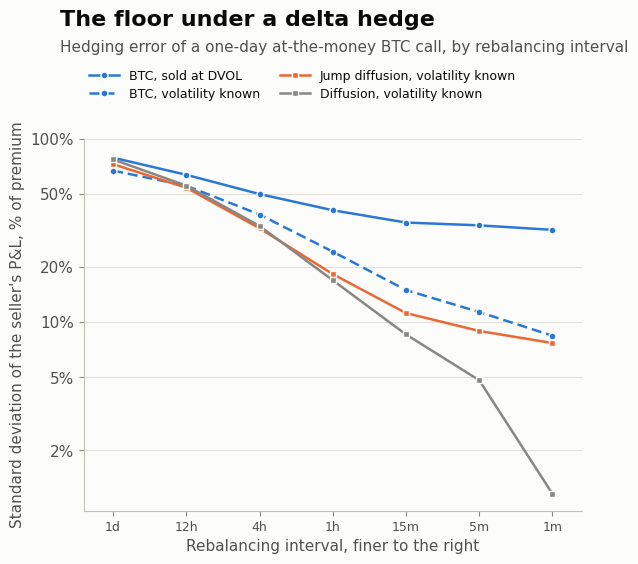

In [3]:
colours = {"BTC, sold at DVOL": jp.BLUE, "BTC, volatility known": jp.BLUE,
           "Jump diffusion, volatility known": jp.ORANGE, "Diffusion, volatility known": jp.MUTED}
styles = {"BTC, volatility known": (0, (4, 2))}
fig = jp.signature_plot(
    [{"name": name, "y": errors[name].to_numpy(), "color": colours[name], "ls": styles.get(name, "-"),
      "marker": "s" if "iffusion" in name else "o"} for name in cases],
    list(STEPS),
    title="The floor under a delta hedge",
    subtitle="Hedging error of a one-day at-the-money BTC call, by rebalancing interval",
    ylabel="Standard deviation of the seller's P&L, % of premium",
    xlabel="Rebalancing interval, finer to the right",
    reference=None, yticks=[2, 5, 10, 20, 50, 100], percent=True, legend=True,
)
jp.save(fig, "05_hedging_error");

Read the four lines from the bottom.

**The diffusion** does what the textbook says. Its error halves each time the number of rebalances quadruples, all the way down: 77% once a day, 17% every hour, 2.3% every minute. That is also the check that the hedging code is right.

**The jump diffusion** follows it for a while and then stops. Below 15 minutes its error stays near 8%. That is the floor jumps leave: a discontinuity cannot be rebalanced through.

**Bitcoin with its volatility known** looks like the jump diffusion. It falls with the diffusion down to four hours, then flattens, and at one minute it stands at 8%, almost four times the diffusion's 2.3%.

**Bitcoin sold at DVOL**, the only line a seller can actually trade, flattens much earlier and much higher. From hourly to one-minute rebalancing the error goes from 41% to 32%.

So there are two floors. Twenty-four points come from not knowing the day's volatility. Eight come from the path. The next two sections take them in turn.

## 2. The first floor: the level of volatility

Over these 2,030 days DVOL averaged 59% and the realized volatility of the following 24 hours averaged 50%, with a correlation of 0.62 between the two. The log of their ratio has a standard deviation of 0.38: a day's realized volatility is routinely 30% below or 45% above the number the option was sold at.

The identity says what that costs. With frequent rebalancing the profit is the gamma-weighted gap between the variance sold and the variance delivered. If the day delivers more than was sold, the seller loses, however well the delta is managed.

In [4]:
one_minute = runs["BTC, sold at DVOL"]["1m"]
profit = one_minute["pnl"] / one_minute["premium"]
print(f"Hedged every minute, sold at DVOL: mean {100 * profit.mean():+.0f}% of premium, standard deviation {100 * profit.std():.0f}%")
print(f"Correlation of the profit with (DVOL - realized) / DVOL: {np.corrcoef(profit, (implied - realised) / implied)[0, 1]:.2f}")
print(f"With the volatility known the standard deviation is {error(runs['BTC, volatility known']['1m']):.1f}%")

Hedged every minute, sold at DVOL: mean +22% of premium, standard deviation 32%
Correlation of the profit with (DVOL - realized) / DVOL: 0.85
With the volatility known the standard deviation is 8.4%


The correlation between the hedged profit and the gap between DVOL and realized volatility is 0.85. A delta hedge at one-minute frequency turns a short option into a bet on realized volatility and very little else. No rebalancing schedule in the underlying can hedge that bet. It takes another option.

The mean is positive: the seller keeps 22% of the premium on average. Part of that is the well-known gap between implied and realized volatility, and part is an artefact of pricing a one-day option off a 30-day index. It is not analysed here.

## 3. The second floor: the timing of volatility

Now give the hedger the day's realized volatility. The level is right by construction. Eight percent of the premium still remains at one-minute rebalancing, against 2.3% for a diffusion.

Posts 3 and 4 found that jumps carry a few percent of Bitcoin's variance at most. Is that enough to explain a floor of this size?

In [5]:
rows = {}
for share in (0.03, 0.10, 0.30):
    sim = hg.simulate_paths(paths[:, 0], realised, N_MIN, jump_share=share, jumps_per_day=1.0, seed=7)
    rows[f"Jump diffusion, {share:.0%} of variance in jumps"] = error(hg.hedge(sim, hg.realised_volatility(sim), 1))
rows["Diffusion"] = error(runs["Diffusion, volatility known"]["1m"])
rows["BTC"] = error(runs["BTC, volatility known"]["1m"])
pd.Series(rows, name="Error at 1-minute rebalancing, volatility known (% of premium)").round(1).to_frame()

,"Error at 1-minute rebalancing, volatility known (% of premium)"
"Jump diffusion, 3% of variance in jumps",1.8
"Jump diffusion, 10% of variance in jumps",3.8
"Jump diffusion, 30% of variance in jumps",7.8
Diffusion,1.2
BTC,8.4


No. A jump diffusion with 3% of its variance in jumps leaves a floor under 2%. To reach Bitcoin's 8% it would need about 30%, ten times what the data allow.

The identity gives the real answer. With the level of variance right on average over the day, the profit still depends on *where in the day* the variance fell, because gamma is not constant: it is highest near the strike and near expiry. Variance that arrives when gamma is high costs more than the same variance arriving when gamma is low.

How fine does the timing need to be to explain the floor? Replace the minute-by-minute identity with a coarse version that only knows the realized variance of each hour, and the average gamma of that hour.

In [6]:
known = runs["BTC, volatility known"]["1m"]["pnl"]
exact = hg.variance_timing(paths, realised, block=1)
print(f"Correlation between the 1-minute hedged profit and the gamma-weighted variance identity: {np.corrcoef(known, exact)[0, 1]:.3f}")
timing = {f"{block // 60} hour" + ("s" if block > 60 else ""): np.corrcoef(known, hg.variance_timing(paths, realised, block))[0, 1] ** 2
          for block in (60, 240)}
print("Share of the variance of that profit explained by which blocks of the day were volatile:")
for label, r2 in timing.items():
    print(f"   blocks of {label}: {100 * r2:.0f}%")

# The predictable part of the timing: hedge on the seasonal volatility clock of post 2.
r5 = se.regular_returns(close_all, 5)
factor, _ = se.seasonal_factor(r5 / se.lee_mykland(r5, 270, 288)["s"],
                               se.week_slot(r5.index, 5, "America/New_York"), 7 * 288, ["2021-01-01", "2024-01-01"])
clock = hg.seasonal_clock(starts, N_MIN, factor)
print(f"\nError at 1 minute, volatility known, delta on the calendar clock: {error(hg.hedge(paths, realised, 1)):.1f}%")
print(f"Error at 1 minute, volatility known, delta on the seasonal volatility clock: {error(hg.hedge(paths, realised, 1, clock=clock)):.1f}%")

Correlation between the 1-minute hedged profit and the gamma-weighted variance identity: 0.998
Share of the variance of that profit explained by which blocks of the day were volatile:
   blocks of 1 hour: 95%
   blocks of 4 hours: 84%



Error at 1 minute, volatility known, delta on the calendar clock: 8.4%
Error at 1 minute, volatility known, delta on the seasonal volatility clock: 7.8%


Knowing only which *hours* were volatile explains 95% of the floor. What happened inside each hour, whether the price jumped or slid, whether a burst lasted one minute or twenty, accounts for the other 5%.

That is the answer to the question of this post. For a delta hedger with a fixed-volatility delta, the irreducible risk in Bitcoin is that volatility is not constant within the life of the option. It makes no difference to the hedge whether a violent hour was made of jumps or of the multi-minute slides of post 1. Either way the variance arrived in a lump, and the lump met whatever gamma was there.

One might hope that the predictable part of the timing helps. Post 2 showed that variance arrives on a schedule, so the delta could count time on the seasonal volatility clock instead of the calendar. It barely moves the result: 8.4% becomes 7.8%. The timing that hurts is not the timing you can see coming.

## 4. What faster rebalancing does remove

Leave the floors and look at the part of the error that rebalancing controls: the difference, path by path, between the profit at a given interval and the profit of the one-minute hedge on the same path.

In [7]:
def discretisation(name):
    base = runs[name]["1m"]
    return {label: 100 * (r["pnl"] / r["premium"] - base["pnl"] / base["premium"]).std()
            for label, r in runs[name].items() if label != "1m"}

disc = pd.DataFrame({"BTC": discretisation("BTC, volatility known"),
                     "Diffusion": discretisation("Diffusion, volatility known")})
disc["BTC / diffusion"] = disc["BTC"] / disc["Diffusion"]

def exponent(column, lo="1h", hi="5m"):
    n = {label: N_MIN / step for label, step in STEPS.items()}
    return np.log(disc.loc[lo, column] / disc.loc[hi, column]) / np.log(n[hi] / n[lo])

print(f"Decay exponent between hourly and 5-minute rebalancing: BTC {exponent('BTC'):.2f}, diffusion {exponent('Diffusion'):.2f}")
disc.round(2).rename_axis("Rebalancing interval")

Decay exponent between hourly and 5-minute rebalancing: BTC 0.44, diffusion 0.52


,BTC,Diffusion,BTC / diffusion
Rebalancing interval,,,
1d,65.35,77.09,0.85
12h,53.36,55.47,0.96
4h,36.25,33.44,1.08
1h,21.71,16.84,1.29
15m,11.98,8.46,1.42
5m,7.35,4.66,1.58


At coarse intervals Bitcoin and the diffusion are indistinguishable. As the interval shrinks, Bitcoin's discretisation error falls more slowly: its exponent between hourly and 5-minute rebalancing is 0.44, against 0.52 for the diffusion, and at 5 minutes the error is 1.6 times the diffusion's. Rebalancing Bitcoin every 5 minutes gives about what rebalancing a diffusion every 12 minutes gives.

The reason is post 4. The error of a discretely rebalanced hedge is driven by the fourth moment of returns over the rebalancing interval, and Bitcoin's returns have a cubic tail at every clock. A few intervals carry most of the damage.

## 5. The price of rebalancing

Every rebalance trades the underlying. The notional traded grows roughly with the square root of the number of rebalances, while the error falls, at best, with its inverse. With a proportional cost the two cross.

Costs are an assumption here: one basis point of the notional traded, about what a large account pays in fees and half-spread on the most liquid venue, and five basis points for comparison.

,Rebalances per day,"Error, sold at DVOL (% of premium)",Notional traded (multiples of spot),Cost at 1 bp (% of premium),Cost at 5 bp (% of premium)
Rebalancing interval,,,,,
1d,1,78.8,1.0,0.9,4.5
12h,2,63.6,1.2,1.1,5.4
4h,6,49.9,1.6,1.4,6.9
1h,24,40.7,2.2,1.9,9.6
15m,96,34.9,3.4,3.0,15.0
5m,288,33.7,5.1,4.5,22.7
1m,1440,31.9,9.9,8.7,43.7


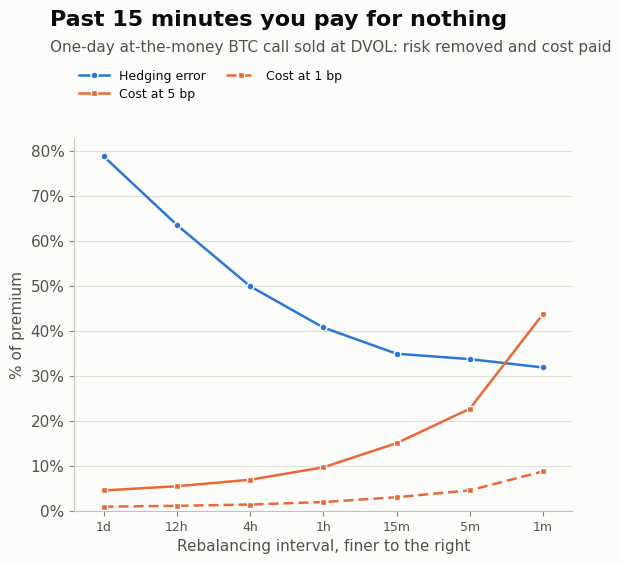

In [8]:
trade = runs["BTC, sold at DVOL"]
cost = pd.DataFrame({
    "Rebalances per day": [N_MIN // s for s in STEPS.values()],
    "Error, sold at DVOL (% of premium)": [error(trade[k]) for k in STEPS],
    "Notional traded (multiples of spot)": [(trade[k]["turnover"] / paths[:, 0]).mean() for k in STEPS],
    "Cost at 1 bp (% of premium)": [1e-4 * 100 * (trade[k]["turnover"] / trade[k]["premium"]).mean() for k in STEPS],
    "Cost at 5 bp (% of premium)": [5e-4 * 100 * (trade[k]["turnover"] / trade[k]["premium"]).mean() for k in STEPS],
}, index=pd.Index(list(STEPS), name="Rebalancing interval"))

fig = jp.signature_plot(
    [{"name": "Hedging error", "y": cost["Error, sold at DVOL (% of premium)"].to_numpy(), "color": jp.BLUE},
     {"name": "Cost at 5 bp", "y": cost["Cost at 5 bp (% of premium)"].to_numpy(), "color": jp.ORANGE, "marker": "s"},
     {"name": "Cost at 1 bp", "y": cost["Cost at 1 bp (% of premium)"].to_numpy(), "color": jp.ORANGE, "marker": "s", "ls": (0, (4, 2))}],
    list(STEPS),
    title="Past 15 minutes you pay for nothing",
    subtitle="One-day at-the-money BTC call sold at DVOL: risk removed and cost paid",
    ylabel="% of premium", xlabel="Rebalancing interval, finer to the right",
    reference=None, log=False, percent=True, ymin=0, legend=True,
)
jp.save(fig, "05_risk_and_cost")
cost.round(1)

Hedging every minute means trading seventeen times the notional of the option in a day. At one basis point that is 14% of the premium, spent to bring the error from 35% to 32%. At five basis points it is 73% of the premium.

The error stops falling at about 15 minutes. The cost never stops rising. Between hourly and 15-minute rebalancing a point of cost at one basis point buys three points of risk; beyond that it buys a fraction of a point.

## 6. The shape of the outcome

Dispersion is one number. A seller also cares which way the tail points.

In [9]:
def shape(run):
    x = 100 * run["pnl"] / run["premium"]
    return {"Mean": x.mean(), "Std": x.std(), "Skewness": stats.skew(x), "Excess kurtosis": stats.kurtosis(x),
            "1% quantile": np.quantile(x, 0.01), "5% quantile": np.quantile(x, 0.05), "Median": np.median(x)}

pd.DataFrame({(name, label): shape(runs[name][label])
              for name in ("BTC, sold at DVOL", "BTC, volatility known") for label in ("1d", "1h", "1m")}).T.round(1)

Mean   Std  Skewness  Excess kurtosis  1% quantile  5% quantile  Median
BTC, sold at DVOL     1d  21.8  78.8      -2.2              7.1       -278.9       -128.6    44.1
                      1h  22.7  40.7      -1.6              7.7       -107.8        -40.6    25.6
                      1m  22.2  31.9      -0.7              2.6        -70.6        -26.2    22.7
BTC, volatility known 1d  13.6  67.0      -1.0              0.8       -179.1       -112.7    29.2
                      1h   7.5  24.2      -0.6              2.1        -60.5        -32.1     8.1
                      1m   4.0   8.4       0.9              1.3        -11.6         -7.1     2.4

Sold at DVOL and hedged every minute, the seller's distribution has a long left tail: the worst day in a hundred loses about the whole premium, against a median gain of a third of it. Frequent hedging does not remove that tail. It is the days when realized volatility ran far above DVOL.

## 7. A one-week option

The same experiment with a 7-day call sold on Fridays at 08:00 UTC, 286 non-overlapping windows. A 30-day index is a better proxy for a one-week volatility than for a one-day one.

In [10]:
w_starts, w_paths, w_implied, w_realised = build(7, weekday=4)
W_STEPS = {"1d": 1440, "4h": 240, "1h": 60, "15m": 15, "5m": 5, "1m": 1}
W_MIN = w_paths.shape[1] - 1
w_diffusion = hg.simulate_paths(w_paths[:, 0], w_realised, W_MIN, seed=3)
week = pd.DataFrame({
    "Rebalances per week": {k: W_MIN // s for k, s in W_STEPS.items()},
    "BTC, sold at DVOL": {k: error(hg.hedge(w_paths, w_implied, s)) for k, s in W_STEPS.items()},
    "BTC, volatility known": {k: error(hg.hedge(w_paths, w_realised, s)) for k, s in W_STEPS.items()},
    "Diffusion, volatility known": {k: error(hg.hedge(w_diffusion, hg.realised_volatility(w_diffusion), s)) for k, s in W_STEPS.items()},
})
print(f"{len(w_starts)} one-week windows. Standard deviation of log(realized / DVOL): {np.std(np.log(w_realised / w_implied)):.2f}")
week.round(1).rename_axis("Rebalancing interval")

286 one-week windows. Standard deviation of log(realized / DVOL): 0.28


,Rebalances per week,"BTC, sold at DVOL","BTC, volatility known","Diffusion, volatility known"
Rebalancing interval,,,,
1d,7,36.2,29.0,31.1
4h,42,25.5,18.7,13.7
1h,168,22.0,11.9,6.9
15m,672,21.1,9.6,3.1
5m,2016,21.5,9.5,1.6
1m,10080,20.9,8.4,0.4


The same picture, with the floors lower and reached sooner. Sold at DVOL the error is 21% to 22% at any interval from one hour down; rebalancing a one-week option more often than hourly removes nothing measurable. With the volatility known the floor is again 8% to 9%, ten times what a diffusion would leave at one minute.

## 8. Caveats

- **The option is synthetic.** Its premium and delta come from Black-Scholes at DVOL, a 30-day index, not from the market's quote for that strike and expiry. That inflates the first floor, the volatility-level risk, since the market's one-day implied volatility tracks one-day realized volatility better than a 30-day index does. It also inflates the mean profit. It does not affect the second floor or the discretisation results, which use the realized volatility of each window.
- **"Volatility known" is not a strategy.** It is a way of taking the level of volatility out of the experiment. Nobody can trade it.
- **The delta is the simplest one.** Fixed volatility, no smile, no correlation between price and volatility. A minimum-variance delta built from the surface is the natural refinement and needs the surface.
- **No jump-aware delta.** The plan for this post compared a Black-Scholes delta with a jump-aware one. Posts 3 and 4 left no jump component worth a model, and section 3 shows that a jump diffusion calibrated to the data would not explain the floor. The seasonal volatility clock was tried instead.
- **Costs are an assumption.** A proportional cost with no market impact. In the moments that matter, spreads are wider than average.
- **Non-overlapping windows from one history.** 2,030 one-day windows and 286 one-week windows. The one-week numbers carry a sampling error of several percent of their value.
- **One strike.** At-the-money only. Gamma is concentrated differently for other strikes and so is the timing risk.

## 9. Takeaways

1. On real Bitcoin paths the hedging error of a one-day at-the-money option stops falling at about 15-minute rebalancing. From there to one minute it goes from 35% to 32% of the premium.
2. The floor is not made of jumps. Three quarters of it is the level of volatility: the option was sold at one number and the day delivered another.
3. The rest is the timing of volatility. Which hours were violent explains 95% of it. Jump or slide inside the hour, it does not matter to the hedge.
4. The part rebalancing does control decays more slowly than in a diffusion, because of the cubic tail of post 4.
5. At one basis point per unit traded, hedging every minute spends 14% of the premium. The risk it removes beyond 15 minutes is three points.
6. A delta hedge turns a short option into a position in realized volatility. Managing that takes options, not more trades in the underlying.

## Equation images for the post

In [11]:
jp.render_equation(r"\mathrm{PnL}=C_0-(S_T-K)^{+}+\sum_j \delta_j\,(S_{t_{j+1}}-S_{t_j})", "05_eq_pnl",
                   "Sell a call, hold delta of the underlying, rebalance every h minutes", fontsize=19)
jp.render_equation(r"\mathrm{PnL}\ \approx\ \dfrac{1}{2}\sum_i \Gamma_i\,S_i^{2}\,(\sigma^{2}\Delta t-r_i^{2})", "05_eq_gamma",
                   "You sold variance evenly through time. You pay for it when it arrives, weighted by gamma.", fontsize=22);

## Data sources

- Binance public archive, spot 1-minute klines: [data.binance.vision](https://data.binance.vision)
- Deribit DVOL, public API endpoint `public/get_volatility_index_data`. Deribit's description of the index: [DVOL, Deribit Implied Volatility Index](https://insights.deribit.com/?p=1813)

No paper is cited in this post. The experiment uses only the Black-Scholes delta, and the diffusion benchmark is simulated with the same code as the data.

---

*Code, data loaders and figures: [github.com/PascalLemieux/jumps](https://github.com/PascalLemieux/jumps). Comments and corrections welcome on [LinkedIn](https://linkedin.com/in/pascal-lemieux).*